# Trajectory Feedback and Nelson's Stochastic Mechanics
### A Monte Carlo tutorial on the Bose et al. (BMV) gravitationally-induced-entanglement experiment

This notebook is a hands-on companion to the trajectory-based feedback model and its connection to Nelson's stochastic mechanics (NSM), as developed in *Gravitationally Induced Entanglement in Pilot-Wave Theory* (M. K. Döner). It follows the same two-particle, feedback-driven approach used in the dissertation's Chapter 4 simulation, but now applied to the Bose et al. experimental setup, and with the explicit goal of comparing two trajectory pictures of the *same* physics side by side:

- **Model A — the trajectory-based (dBB/CWF) feedback model.** Particle trajectories are deterministic given an initial condition; each particle's conditional wave function (CWF) is fed back on by the other particle's actual trajectory.
- **Model B — Nelson's stochastic mechanics (NSM).** The same guidance dynamics, plus an osmotic drift sourced by the density and explicit Brownian noise.

Both models share the same underlying guidance velocity (the kinematic correspondence established in the paper), but Model B reintroduces genuine stochasticity, which is what makes a **Monte Carlo** approach essential here: a single Nelson trajectory means little on its own, but an *ensemble* of them lets us recover density predictions and entanglement diagnostics that can be checked directly against the trajectory-based model.

**What you'll see by the end of this notebook:**
1. How the Bose et al. branch structure and gravitational phases are built into a closed-form wave function.
2. How the conditional wave function (CWF) and guidance equation work, and how the feedback loop emerges.
3. How Nelson's osmotic velocity is defined, and why it requires keeping branch overlap (not the idealised well-separated limit).
4. A full Monte Carlo comparison of Model A and Model B trajectories.
5. The key diagnostic: the **osmotic velocity difference** $\delta u^{\rm osm}_1$, and its direct, numerically verified relationship to the growth of entanglement.
6. A **dynamical equilibrium** check: does the Monte Carlo ensemble's distribution track the analytically predicted $|\Psi|^2$ marginal over time?


## Background: two pictures of the same physics

In the paper, the de Broglie–Bohm / conditional-wave-function (CWF) feedback formalism and Nelson's stochastic mechanics are shown to share the same kinematic skeleton: the *current velocity* in Nelson's theory is identical to the dBB guidance velocity once $\nu = \hbar/2m$ is identified. What Nelson's theory adds is an *osmotic velocity* $u^{\rm osm} = \nu\,\nabla\ln\rho$, sourced by the density $\rho$, plus genuine Brownian noise.

A particularly useful diagnostic falls out of this correspondence. There are *two* natural osmotic velocities one can assign to a particle in an entangled two-body system:

- one computed from the full **marginal** density $\rho_1(x,t) = \int dx_2\,|\Psi(t,x,x_2)|^2$,
- one computed from the **CWF density alone**, $R_1^2(t,x) = |\psi_1(t,x)|^2$.

These two coincide exactly when the joint state $\Psi$ is separable, and differ once entanglement develops. Their difference, $\delta u^{\rm osm}_1$, is therefore a genuine, trajectory-level diagnostic of entanglement growth — the Nelson-theoretic counterpart of the feedback term $F_2$ in the CWF formalism. This notebook builds both quantities explicitly and verifies their relationship numerically.


## Setup

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass

plt.rcParams["figure.dpi"] = 110
rng_global = np.random.default_rng(0)
print("Ready.")

Ready.


## Part 1 — The Bose et al. (BMV) experimental setup

Each particle is prepared in a superposition of two spatial branches, $|L\rangle$ and $|R\rangle$, by a Stern–Gerlach-type apparatus. We represent each branch by a real, normalised Gaussian wave packet $\chi_s(x)$ centred at the branch position $u_k^{s}$ (no carrier momentum — consistent with the BMV approximation that kinetic terms are negligible during the gravity-only "Step 2" interval). The branch positions follow the paper's convention: particle 1 on the left, particle 2 on the right, with the *inner* branches (particle 1's $R$, particle 2's $L$) the closer pair.

During Step 2 (duration $\tau$), the mutual Newtonian interaction imprints branch-dependent phases. Using Bose et al.'s closed-form result (kinetic terms neglected),

$$
\Gamma(t) = \frac{G m^2 t}{\hbar}, \qquad
\Delta\phi_{LR}(t) = \Gamma(t)\left[\frac{1}{d+\Delta x} - \frac{1}{d}\right], \qquad
\Delta\phi_{RL}(t) = \Gamma(t)\left[\frac{1}{d-\Delta x} - \frac{1}{d}\right],
$$

so that the (unnormalised) joint wave function is exactly

$$
\Psi(x_1,x_2,t) = \chi_L(x_1)\chi_L(x_2) + e^{i\Delta\phi_{LR}(t)}\chi_L(x_1)\chi_R(x_2) + e^{i\Delta\phi_{RL}(t)}\chi_R(x_1)\chi_L(x_2) + \chi_R(x_1)\chi_R(x_2).
$$

This closed form means every trajectory-level quantity below — CWF, guidance velocity, marginal and CWF densities, osmotic velocity difference — reduces to elementary functions of the two actual particle positions. No spatial grid or PDE solver is required for this first build.

**A note on branch overlap.** If the branch width $\sigma$ is much smaller than the branch separation $\Delta x$ (the "well separated" limit), the marginal density and the CWF density reduce, *within* the support of either branch, to the *same* single-Gaussian shape — making $\delta u^{\rm osm}$ trivially zero everywhere a trajectory actually visits. Entanglement, in this toy model, only shows up as a local density-gradient effect when the branches genuinely overlap in space. We therefore keep the branch-overlap integral exact throughout (no well-separated approximation).


In [15]:
@dataclass
class Params:
    hbar: float = 1.054571817e-34   # J s
    G: float = 6.67430e-11          # m^3 kg^-1 s^-2
    m: float = 1.0e-14              # kg (each particle, Bose et al. proposal)
    d: float = 450e-6               # m (centre-to-centre separation)
    delta_x: float = 250e-6         # m (branch separation)
    sigma: float = 70e-6            # m (Gaussian branch width)
    tau: float = 2.5                # s (duration of Step 2)
    n_steps: int = 300              # number of time steps
    n_traj: int = 300               # Monte Carlo ensemble size
    seed: int = 0
    eps: float = 1e-30              # regularisation for 1/(...) terms

p = Params()
print(p)

Params(hbar=1.054571817e-34, G=6.6743e-11, m=1e-14, d=0.00045, delta_x=0.00025, sigma=7e-05, tau=2.5, n_steps=300, n_traj=300, seed=0, eps=1e-30)


In [16]:
def chi(x, u, sigma):
    '''Real, unit-normalised Gaussian branch wave packet centred at u.'''
    norm = (2.0 * np.pi * sigma**2) ** (-0.25)
    return norm * np.exp(-(x - u) ** 2 / (4.0 * sigma ** 2))

def dchi_dx(x, u, sigma):
    '''d chi_s(x)/dx.'''
    return -(x - u) / (2.0 * sigma ** 2) * chi(x, u, sigma)

def branch_overlap(delta, sigma):
    '''Overlap integral of two unit-normalised Gaussians separated by delta.'''
    return np.exp(-delta ** 2 / (8.0 * sigma ** 2))

def branch_positions(p: Params):
    '''Branch centres: particle 1 on the left, particle 2 on the right;
    the RL pairing is the closer one (separation d - delta_x), LR the
    farther one (d + delta_x) -- matching alpha, beta in the paper.'''
    u1L = -p.d / 2 - p.delta_x / 2
    u1R = -p.d / 2 + p.delta_x / 2
    u2L = p.d / 2 - p.delta_x / 2
    u2R = p.d / 2 + p.delta_x / 2
    return u1L, u1R, u2L, u2R

def gravitational_phases(t, p: Params):
    '''Bose et al. closed-form differential phases.'''
    Gamma = p.G * p.m ** 2 * t / p.hbar
    dphi_LR = Gamma * (1.0 / (p.d + p.delta_x) - 1.0 / p.d)
    dphi_RL = Gamma * (1.0 / (p.d - p.delta_x) - 1.0 / p.d)
    return dphi_LR, dphi_RL

def phase_scale(t, p: Params):
    '''Combined differential-phase scale sqrt(alpha^2+beta^2).'''
    a, b = gravitational_phases(t, p)
    return np.sqrt(a ** 2 + b ** 2)

uL1, uR1, uL2, uR2 = branch_positions(p)
O = branch_overlap(p.delta_x, p.sigma)
print(f"Branch positions (um): u1L={uL1*1e6:.1f}, u1R={uR1*1e6:.1f}, u2L={uL2*1e6:.1f}, u2R={uR2*1e6:.1f}")
print(f"Branch overlap O = {O:.4f}")
print(f"Phase scale at t=tau: {phase_scale(p.tau, p):.4f} rad")

Branch positions (um): u1L=-350.0, u1R=-100.0, u2L=100.0, u2R=350.0
Branch overlap O = 0.2030
Phase scale at t=tau: 0.4571 rad


Let's visualise the branch structure and how the differential phases grow over Step 2.

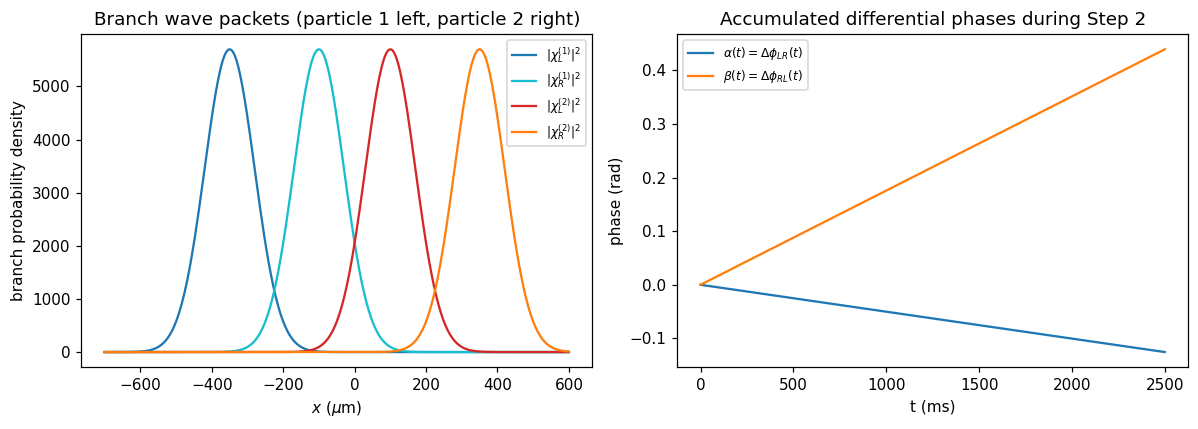

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

xs = np.linspace(-700e-6, 600e-6, 400) * 1e6
ax = axes[0]
ax.plot(xs, chi(xs*1e-6, uL1, p.sigma)**2, label=r"$|\chi_L^{(1)}|^2$", color="tab:blue")
ax.plot(xs, chi(xs*1e-6, uR1, p.sigma)**2, label=r"$|\chi_R^{(1)}|^2$", color="tab:cyan")
ax.plot(xs, chi(xs*1e-6, uL2, p.sigma)**2, label=r"$|\chi_L^{(2)}|^2$", color="tab:red")
ax.plot(xs, chi(xs*1e-6, uR2, p.sigma)**2, label=r"$|\chi_R^{(2)}|^2$", color="tab:orange")
ax.set_xlabel(r"$x$ ($\mu$m)")
ax.set_ylabel("branch probability density")
ax.set_title("Branch wave packets (particle 1 left, particle 2 right)")
ax.legend(fontsize=8)

t_arr = np.linspace(0, p.tau, 200)
a, b = gravitational_phases(t_arr, p)
ax = axes[1]
ax.plot(t_arr*1e3, a, label=r"$\alpha(t)=\Delta\phi_{LR}(t)$")
ax.plot(t_arr*1e3, b, label=r"$\beta(t)=\Delta\phi_{RL}(t)$")
ax.set_xlabel("t (ms)")
ax.set_ylabel("phase (rad)")
ax.set_title("Accumulated differential phases during Step 2")
ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

## Part 2 — Conditional wave functions and the guidance equation

The conditional wave function (CWF) of particle 1 is the universal wave function sliced at particle 2's actual trajectory: $\psi_1(t,x) \equiv \Psi(t,x,X_2(t))$. Grouping the four branch terms of $\Psi$ by their $x_1$-dependence gives a clean two-term form,

$$
\psi_1(x,t) = A_1(t)\,\chi_L(x) + B_1(t)\,\chi_R(x), \qquad
A_1(t) = \chi_L(X_2(t)) + e^{i\Delta\phi_{LR}(t)}\chi_R(X_2(t)), \qquad
B_1(t) = e^{i\Delta\phi_{RL}(t)}\chi_L(X_2(t)) + \chi_R(X_2(t)),
$$

and symmetrically for $\psi_2$. This is the feedback coupling made explicit: the *shape* of particle 1's CWF depends, at every instant, on particle 2's *actual* position $X_2(t)$ — exactly the trajectory-conditioned dependence the paper's CWF formalism is built on.

The guidance equation (shared by both dBB and Nelson's *current velocity*) is

$$
\dot X_1(t) = \frac{\hbar}{m}\,\mathrm{Im}\!\left[\frac{\psi_1'(X_1(t))}{\psi_1(X_1(t))}\right].
$$

Because $\psi_1$ is just a two-term Gaussian superposition with known coefficients, this guidance velocity is fully analytic — no PDE solve needed.


In [18]:
def cwf_coeffs_1(X2, dphi_LR, dphi_RL, uL, uR, sigma):
    '''A_1(t), B_1(t): coefficients of psi_1 = A_1 chi_L + B_1 chi_R.'''
    cL2, cR2 = chi(X2, uL, sigma), chi(X2, uR, sigma)
    A1 = cL2 + np.exp(1j * dphi_LR) * cR2
    B1 = np.exp(1j * dphi_RL) * cL2 + cR2
    return A1, B1

def cwf_coeffs_2(X1, dphi_LR, dphi_RL, uL, uR, sigma):
    '''A_2(t), B_2(t): coefficients of psi_2 = A_2 chi_L + B_2 chi_R.'''
    cL1, cR1 = chi(X1, uL, sigma), chi(X1, uR, sigma)
    A2 = cL1 + np.exp(1j * dphi_RL) * cR1
    B2 = np.exp(1j * dphi_LR) * cL1 + cR1
    return A2, B2

def guidance_velocity(x, A, B, uL, uR, sigma, hbar, m, eps):
    '''v = (hbar/m) Im[psi'(x)/psi(x)] for psi(x) = A chi_L(x) + B chi_R(x).'''
    cL, cR = chi(x, uL, sigma), chi(x, uR, sigma)
    dcL, dcR = dchi_dx(x, uL, sigma), dchi_dx(x, uR, sigma)
    psi = A * cL + B * cR
    dpsi = A * dcL + B * dcR
    return (hbar / m) * np.imag(dpsi / (psi + eps))

# Quick sanity check: guidance velocity for a trajectory sitting in branch L of particle 1,
# with particle 2 in branch L too (both close to t=0, negligible entanglement yet)
X1_test, X2_test = uL1, uL2
dphi_LR0, dphi_RL0 = gravitational_phases(0.0, p)
A1, B1 = cwf_coeffs_1(X2_test, dphi_LR0, dphi_RL0, uL2, uR2, p.sigma)
v1 = guidance_velocity(X1_test, A1, B1, uL1, uR1, p.sigma, p.hbar, p.m, p.eps)
print(f"Guidance velocity at t=0 (no entanglement yet): {v1:.3e} m/s")

Guidance velocity at t=0 (no entanglement yet): 0.000e+00 m/s


## Part 3 — The feedback loop: a single deterministic trajectory (Model A)

In the trajectory-based (dBB/CWF) model, particle 1's CWF $\psi_1$ depends on $X_2(t)$, which in turn is guided by particle 2's CWF $\psi_2$, which depends on $X_1(t)$ — the feedback loop described in the paper. In our closed-form model this loop is automatically self-consistent at every time step: we simply re-evaluate $A_1(t), B_1(t)$ (and $A_2(t), B_2(t)$) using the *current* trajectory positions before taking the next guidance step.

Let's integrate a single pair of trajectories with simple Euler stepping, to see the feedback loop in action before scaling up to a full Monte Carlo ensemble.


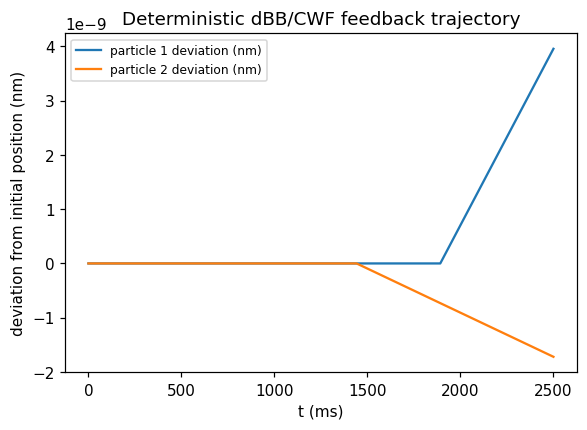

Total displacement of particle 1 over Step 2: 3.957e-09 nm


In [19]:
def integrate_dbb_single(X1_0, X2_0, p: Params):
    '''Single deterministic dBB/CWF feedback trajectory pair.'''
    dt = p.tau / p.n_steps
    t_arr = np.linspace(0.0, p.tau, p.n_steps + 1)
    X1 = np.empty(p.n_steps + 1); X2 = np.empty(p.n_steps + 1)
    X1[0], X2[0] = X1_0, X2_0
    for n in range(p.n_steps):
        t = t_arr[n]
        dphi_LR, dphi_RL = gravitational_phases(t, p)
        A1, B1 = cwf_coeffs_1(X2[n], dphi_LR, dphi_RL, uL2, uR2, p.sigma)
        A2, B2 = cwf_coeffs_2(X1[n], dphi_LR, dphi_RL, uL1, uR1, p.sigma)
        v1 = guidance_velocity(X1[n], A1, B1, uL1, uR1, p.sigma, p.hbar, p.m, p.eps)
        v2 = guidance_velocity(X2[n], A2, B2, uL2, uR2, p.sigma, p.hbar, p.m, p.eps)
        X1[n+1] = X1[n] + v1 * dt
        X2[n+1] = X2[n] + v2 * dt
    return t_arr, X1, X2

t_demo, X1_demo, X2_demo = integrate_dbb_single(uL1, uL2, p)

fig, ax = plt.subplots(figsize=(6,4))
ax.plot(t_demo*1e3, (X1_demo - X1_demo[0])*1e9, label="particle 1 deviation (nm)")
ax.plot(t_demo*1e3, (X2_demo - X2_demo[0])*1e9, label="particle 2 deviation (nm)")
ax.set_xlabel("t (ms)")
ax.set_ylabel("deviation from initial position (nm)")
ax.set_title("Deterministic dBB/CWF feedback trajectory")
ax.legend(fontsize=8)
plt.show()
print(f"Total displacement of particle 1 over Step 2: {(X1_demo[-1]-X1_demo[0])*1e9:.3e} nm")

You'll notice the displacement is extremely small — of order $10^{-9}\,$nm or less. This is not a bug: at the Bose et al. mass scale ($m\sim10^{-14}\,$kg), gravity is simply too weak to move the wave packets appreciably within a few seconds. The interesting physics at this scale lives in the *phase* structure of the wave function, not in visible center-of-mass motion — which is exactly why the osmotic-velocity diagnostic (built from density gradients, themselves driven by the evolving phases) will turn out to be the much more informative quantity, as we'll see in Part 6.


## Part 4 — From dBB to Nelson: the osmotic velocity

Nelson's stochastic mechanics adds, on top of the shared guidance ("current") velocity, an **osmotic velocity** $u^{\rm osm} = \nu\,\nabla\ln\rho$ with $\nu=\hbar/2m$, sourced by the density $\rho$ of the process. For our two-particle system there are two natural choices of density for particle 1:

- the **marginal density**, $\rho_1(x,t) = \int dx_2\,|\Psi(t,x,x_2)|^2$ — the true single-particle density of the full entangled state;
- the **CWF density**, $R_1^2(t,x) = |\psi_1(t,x)|^2$ — the density associated with the conditional wave function alone.

Both reduce to the same two-branch functional form $f(x) = c_{LL}|\chi_L(x)|^2 + c_{RR}|\chi_R(x)|^2 + 2c_{LR}\chi_L(x)\chi_R(x)$, just with different coefficient triples — which lets us reuse a single helper function for both.

For the **marginal** density, integrating $|\Psi|^2$ over the other particle's coordinate (keeping the branch-overlap integral $O$ exact) gives coefficients

$$
w_{LL}(t) = 2+2O\cos\Delta\phi_{LR}(t), \qquad
w_{RR}(t) = 2+2O\cos\Delta\phi_{RL}(t), \qquad
w_{LR}(t) = \cos\Delta\phi_{RL}(t)+\cos\Delta\phi_{LR}(t)+O\big[1+\cos(\Delta\phi_{LR}-\Delta\phi_{RL})\big].
$$

For the **CWF** density, the coefficients are simply $|A_1(t)|^2, |B_1(t)|^2, \mathrm{Re}[A_1(t)B_1^*(t)]$ — the same $A_1, B_1$ already built in Part 2, now evaluated at the *actual* trajectory.


In [20]:
def density_and_grad(x, c_LL, c_RR, c_LR, uL, uR, sigma):
    '''Shared two-branch density form f(x) and its derivative f'(x).'''
    cL, cR = chi(x, uL, sigma), chi(x, uR, sigma)
    dcL, dcR = dchi_dx(x, uL, sigma), dchi_dx(x, uR, sigma)
    f = c_LL * cL ** 2 + c_RR * cR ** 2 + 2.0 * c_LR * cL * cR
    df = (2.0 * c_LL * cL * dcL + 2.0 * c_RR * cR * dcR
          + 2.0 * c_LR * (dcL * cR + cL * dcR))
    return f, df

def marginal_weights(dphi_LR, dphi_RL, O):
    '''w_LL(t), w_RR(t), w_LR(t) for the marginal density rho_1.'''
    w_LL = 2.0 + 2.0 * O * np.cos(dphi_LR)
    w_RR = 2.0 + 2.0 * O * np.cos(dphi_RL)
    w_LR = np.cos(dphi_RL) + np.cos(dphi_LR) + O * (1.0 + np.cos(dphi_LR - dphi_RL))
    return w_LL, w_RR, w_LR

def osmotic_velocity(x, c_LL, c_RR, c_LR, uL, uR, sigma, hbar, m, eps):
    '''u^osm(x) = (hbar/2m) d ln f / dx, for the shared density form f(x).'''
    f, df = density_and_grad(x, c_LL, c_RR, c_LR, uL, uR, sigma)
    return (hbar / (2.0 * m)) * df / (f + eps)

Let's visualise the marginal density at $t=\tau$ (some entanglement has built up) and compare its shape to a CWF density evaluated at a specific particle-2 position.

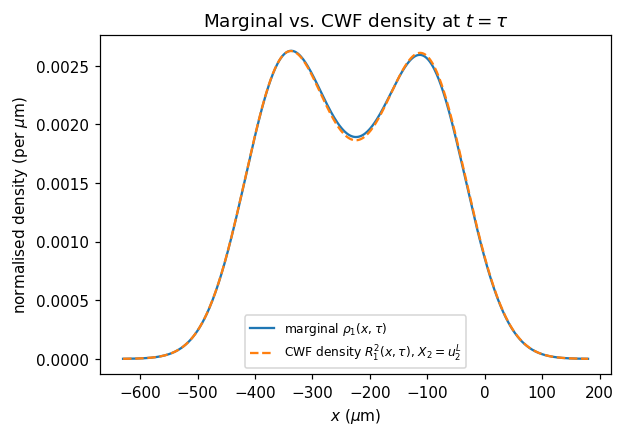

In [21]:
x_min = min(uL1, uR1) - 4*p.sigma
x_max = max(uL1, uR1) + 4*p.sigma
xs = np.linspace(x_min, x_max, 600)

dphi_LR_tau, dphi_RL_tau = gravitational_phases(p.tau, p)
w_LL, w_RR, w_LR = marginal_weights(dphi_LR_tau, dphi_RL_tau, O)
rho1, _ = density_and_grad(xs, w_LL, w_RR, w_LR, uL1, uR1, p.sigma)
rho1_normed = rho1 / np.trapezoid(rho1, xs)

# CWF density for a specific instance of X2 sitting in branch L
X2_example = uL2
A1e, B1e = cwf_coeffs_1(X2_example, dphi_LR_tau, dphi_RL_tau, uL2, uR2, p.sigma)
R1sq, _ = density_and_grad(xs, np.abs(A1e)**2, np.abs(B1e)**2, np.real(A1e*np.conj(B1e)), uL1, uR1, p.sigma)
R1sq_normed = R1sq / np.trapezoid(R1sq, xs)

fig, ax = plt.subplots(figsize=(6,4))
ax.plot(xs*1e6, rho1_normed*1e-6, label=r"marginal $\rho_1(x,\tau)$")
ax.plot(xs*1e6, R1sq_normed*1e-6, label=r"CWF density $R_1^2(x,\tau)$, $X_2=u_2^L$", linestyle="--")
ax.set_xlabel(r"$x$ ($\mu$m)")
ax.set_ylabel(r"normalised density (per $\mu$m)")
ax.set_title(r"Marginal vs. CWF density at $t=\tau$")
ax.legend(fontsize=8)
plt.show()

The two density shapes are visibly different: the marginal density reflects branch weights built from *both* particles' phase history, while the CWF density is conditioned on one specific (here, fixed) value of $X_2$. This difference is exactly what $\delta u^{\rm osm}_1$ will measure.

## Part 5 — Monte Carlo simulation: Model A vs. Model B

We now build the full ensemble simulation. Initial conditions are sampled according to the Born rule: each particle starts in branch $L$ or $R$ with probability $1/2$, and within the chosen branch its position is drawn from $\mathrm{Normal}(u^{s},\sigma)$ — matching $|\chi_s(x)|^2$. Both models share the *same* initial ensemble, so trajectory $i$ in Model A and trajectory $i$ in Model B start from an identical point, differing only in their subsequent dynamics:

- **Model A** evolves by the guidance velocity alone (Euler integration).
- **Model B** evolves by the guidance velocity *plus* the osmotic drift (from the marginal density) *plus* Wiener noise with diffusion coefficient $\nu=\hbar/2m$ (Euler–Maruyama integration).

At each step we also evaluate the **osmotic velocity difference** along the Model B trajectory:
$$
\delta u^{\rm osm}_1(t) = u^{\rm osm}_1(X_1(t),t) - u^{\rm osm,\,CWF}_1(X_1(t),t).
$$


In [22]:
def sample_initial_conditions(p: Params, rng):
    u1L, u1R, u2L, u2R = branch_positions(p)
    s1 = rng.integers(0, 2, size=p.n_traj)
    s2 = rng.integers(0, 2, size=p.n_traj)
    u1_branch = np.where(s1 == 0, u1L, u1R)
    u2_branch = np.where(s2 == 0, u2L, u2R)
    X1_0 = rng.normal(u1_branch, p.sigma)
    X2_0 = rng.normal(u2_branch, p.sigma)
    return X1_0, X2_0, u1_branch, u2_branch


def run_simulation(p: Params):
    rng = np.random.default_rng(p.seed)
    uL1, uR1, uL2, uR2 = branch_positions(p)
    O = branch_overlap(p.delta_x, p.sigma)

    dt = p.tau / p.n_steps
    t_arr = np.linspace(0.0, p.tau, p.n_steps + 1)

    X1_0, X2_0, u1_branch, u2_branch = sample_initial_conditions(p, rng)

    X1_A = np.empty((p.n_steps + 1, p.n_traj)); X2_A = np.empty_like(X1_A)
    X1_B = np.empty((p.n_steps + 1, p.n_traj)); X2_B = np.empty_like(X1_A)
    X1_A[0], X2_A[0] = X1_0, X2_0
    X1_B[0], X2_B[0] = X1_0, X2_0

    nu = p.hbar / (2.0 * p.m)
    sqrt2nudt = np.sqrt(2.0 * nu * dt)

    delta_uosm = np.empty((p.n_steps + 1, p.n_traj))
    delta_uosm[0] = 0.0

    for n in range(p.n_steps):
        t = t_arr[n]
        dphi_LR, dphi_RL = gravitational_phases(t, p)
        w_LL, w_RR, w_LR = marginal_weights(dphi_LR, dphi_RL, O)

        # ---- Model A: deterministic guidance update -----------------
        A1, B1 = cwf_coeffs_1(X2_A[n], dphi_LR, dphi_RL, uL2, uR2, p.sigma)
        A2, B2 = cwf_coeffs_2(X1_A[n], dphi_LR, dphi_RL, uL1, uR1, p.sigma)
        v1_A = guidance_velocity(X1_A[n], A1, B1, uL1, uR1, p.sigma, p.hbar, p.m, p.eps)
        v2_A = guidance_velocity(X2_A[n], A2, B2, uL2, uR2, p.sigma, p.hbar, p.m, p.eps)
        X1_A[n+1] = X1_A[n] + v1_A * dt
        X2_A[n+1] = X2_A[n] + v2_A * dt

        # ---- Model B: Nelson SDE update ------------------------------
        A1b, B1b = cwf_coeffs_1(X2_B[n], dphi_LR, dphi_RL, uL2, uR2, p.sigma)
        A2b, B2b = cwf_coeffs_2(X1_B[n], dphi_LR, dphi_RL, uL1, uR1, p.sigma)
        v1_B = guidance_velocity(X1_B[n], A1b, B1b, uL1, uR1, p.sigma, p.hbar, p.m, p.eps)
        v2_B = guidance_velocity(X2_B[n], A2b, B2b, uL2, uR2, p.sigma, p.hbar, p.m, p.eps)

        u1_osm = osmotic_velocity(X1_B[n], w_LL, w_RR, w_LR, uL1, uR1, p.sigma, p.hbar, p.m, p.eps)
        u2_osm = osmotic_velocity(X2_B[n], w_RR, w_LL, w_LR, uL2, uR2, p.sigma, p.hbar, p.m, p.eps)

        dW1 = rng.normal(0.0, sqrt2nudt, size=p.n_traj)
        dW2 = rng.normal(0.0, sqrt2nudt, size=p.n_traj)

        X1_B[n+1] = X1_B[n] + (v1_B + u1_osm) * dt + dW1
        X2_B[n+1] = X2_B[n] + (v2_B + u2_osm) * dt + dW2

        # ---- Diagnostic at the new Nelson state -----------------------
        dphi_LR1, dphi_RL1 = gravitational_phases(t_arr[n+1], p)
        w_LL1, w_RR1, w_LR1 = marginal_weights(dphi_LR1, dphi_RL1, O)
        A1c, B1c = cwf_coeffs_1(X2_B[n+1], dphi_LR1, dphi_RL1, uL2, uR2, p.sigma)

        u_marg = osmotic_velocity(X1_B[n+1], w_LL1, w_RR1, w_LR1, uL1, uR1, p.sigma, p.hbar, p.m, p.eps)
        u_cwf = osmotic_velocity(
            X1_B[n+1], np.abs(A1c)**2, np.abs(B1c)**2,
            np.real(A1c*np.conj(B1c)), uL1, uR1, p.sigma, p.hbar, p.m, p.eps
        )
        delta_uosm[n+1] = u_marg - u_cwf

    return {
        "t": t_arr, "X1_A": X1_A, "X2_A": X2_A, "X1_B": X1_B, "X2_B": X2_B,
        "delta_uosm": delta_uosm, "phase_scale": phase_scale(t_arr, p),
        "u1_branch": u1_branch, "u2_branch": u2_branch,
    }

In [23]:
import time
t0 = time.time()
res = run_simulation(p)
print(f"Simulation complete in {time.time()-t0:.2f} s "
      f"({p.n_traj} trajectories x {p.n_steps} steps, both models).")

Simulation complete in 0.28 s (300 trajectories x 300 steps, both models).


## Part 6 — Results: trajectories

As we already saw for a single trajectory in Part 3, the absolute position scale of guidance-driven motion is far too small to see directly. We therefore plot the **deviation from initial position**, in nanometres, which makes the qualitative distinction between the two models visible: Model A (deterministic dBB/CWF) stays essentially flat, while Model B (Nelson) shows visible diffusive (Brownian) wandering, with its ensemble spread growing as $\sqrt{t}$.


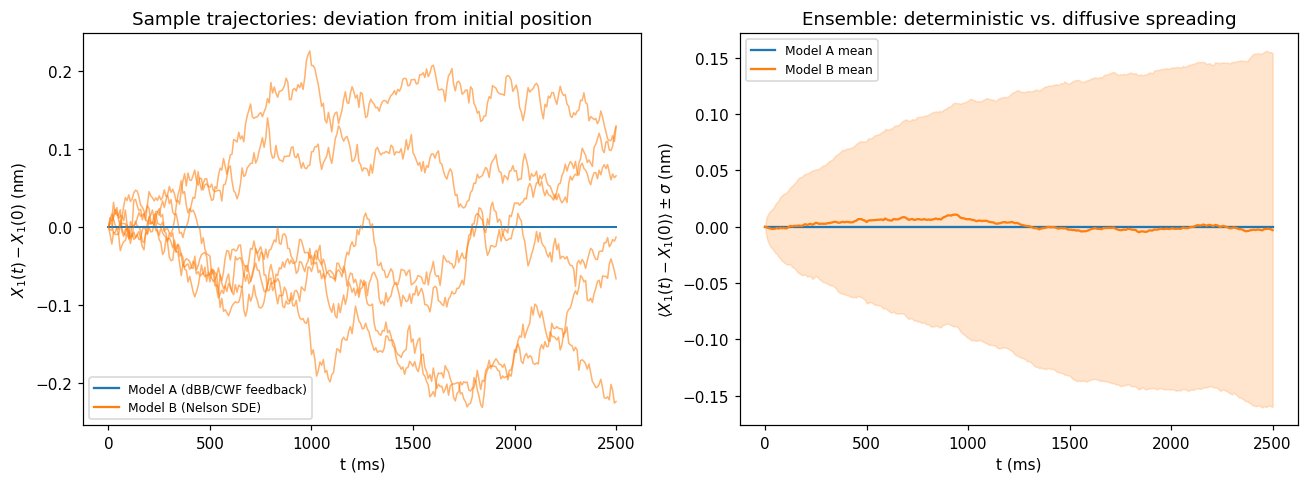

In [24]:
nm = 1e9
n_show = 6
rng_show = np.random.default_rng(1)
idx = rng_show.choice(p.n_traj, size=n_show, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
for i in idx:
    devA = (res["X1_A"][:, i] - res["X1_A"][0, i]) * nm
    devB = (res["X1_B"][:, i] - res["X1_B"][0, i]) * nm
    ax.plot(res["t"]*1e3, devA, color="tab:blue", alpha=0.6, lw=1.2)
    ax.plot(res["t"]*1e3, devB, color="tab:orange", alpha=0.6, lw=1.0)
ax.plot([], [], color="tab:blue", label="Model A (dBB/CWF feedback)")
ax.plot([], [], color="tab:orange", label="Model B (Nelson SDE)")
ax.set_xlabel("t (ms)"); ax.set_ylabel(r"$X_1(t)-X_1(0)$ (nm)")
ax.set_title("Sample trajectories: deviation from initial position")
ax.legend(fontsize=8)

ax = axes[1]
devA_all = (res["X1_A"] - res["X1_A"][0:1]) * nm
devB_all = (res["X1_B"] - res["X1_B"][0:1]) * nm
meanA, stdA = devA_all.mean(axis=1), devA_all.std(axis=1)
meanB, stdB = devB_all.mean(axis=1), devB_all.std(axis=1)
ax.plot(res["t"]*1e3, meanA, color="tab:blue", label="Model A mean")
ax.fill_between(res["t"]*1e3, meanA-stdA, meanA+stdA, color="tab:blue", alpha=0.2)
ax.plot(res["t"]*1e3, meanB, color="tab:orange", label="Model B mean")
ax.fill_between(res["t"]*1e3, meanB-stdB, meanB+stdB, color="tab:orange", alpha=0.2)
ax.set_xlabel("t (ms)"); ax.set_ylabel(r"$\langle X_1(t)-X_1(0)\rangle\pm\sigma$ (nm)")
ax.set_title("Ensemble: deterministic vs. diffusive spreading")
ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

## Part 7 — The key diagnostic: $\delta u^{\rm osm}_1$ vs. accumulated phase

This is the central comparison this notebook was built for. The osmotic velocity difference $\delta u^{\rm osm}_1$ is, by construction, the Nelson-theoretic counterpart of the feedback term: both are zero for a separable state and grow as the differential phases $\alpha(t), \beta(t)$ accumulate.

We compare $\langle|\delta u^{\rm osm}_1|\rangle$ directly against the combined phase scale $\sqrt{\alpha(t)^2+\beta(t)^2}$, and then check the **growth rate** on a log-log plot against a reference quadratic line, $\propto(\alpha^2+\beta^2)$.


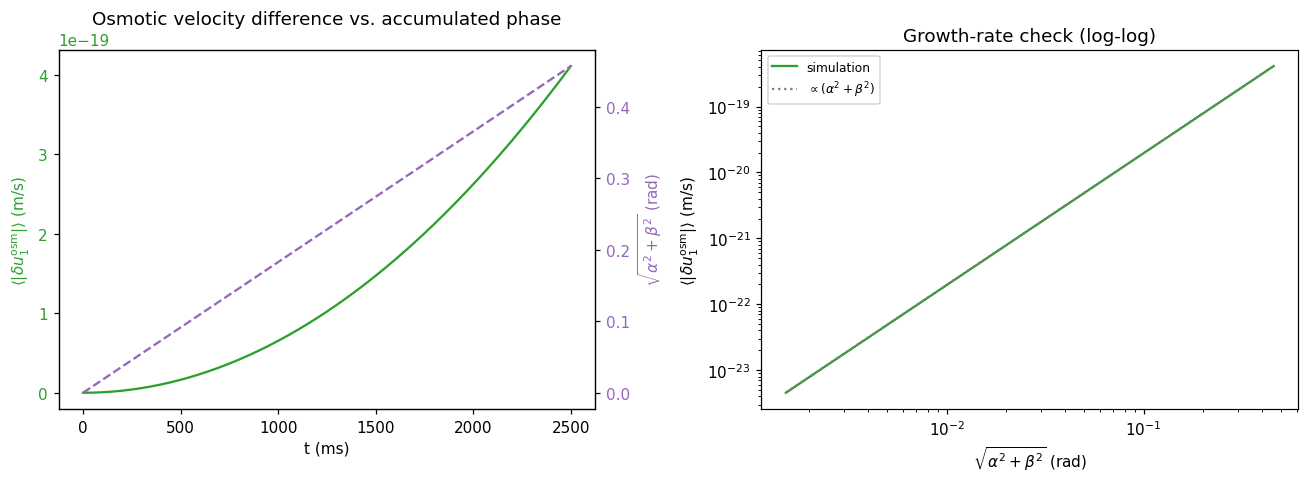

Final |delta_u_osm| (t=tau): 4.1117e-19 m/s
Final phase scale (t=tau):   4.5710e-01 rad


In [25]:
mean_duosm = np.abs(res["delta_uosm"]).mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
ax.plot(res["t"]*1e3, mean_duosm, color="tab:green")
ax.set_xlabel("t (ms)")
ax.set_ylabel(r"$\langle|\delta u^{\rm osm}_1|\rangle$ (m/s)", color="tab:green")
ax.tick_params(axis="y", labelcolor="tab:green")
ax.set_title("Osmotic velocity difference vs. accumulated phase")
ax2 = ax.twinx()
ax2.plot(res["t"]*1e3, res["phase_scale"], color="tab:purple", linestyle="--")
ax2.set_ylabel(r"$\sqrt{\alpha^2+\beta^2}$ (rad)", color="tab:purple")
ax2.tick_params(axis="y", labelcolor="tab:purple")

ax = axes[1]
mask = (res["phase_scale"] > 0) & (mean_duosm > 0)
ax.loglog(res["phase_scale"][mask], mean_duosm[mask], color="tab:green", lw=1.5, label="simulation")
ref_x = res["phase_scale"][mask]
ref_y = mean_duosm[mask][-1] * (ref_x / ref_x[-1]) ** 2
ax.loglog(ref_x, ref_y, color="gray", linestyle=":", label=r"$\propto(\alpha^2+\beta^2)$")
ax.set_xlabel(r"$\sqrt{\alpha^2+\beta^2}$ (rad)")
ax.set_ylabel(r"$\langle|\delta u^{\rm osm}_1|\rangle$ (m/s)")
ax.set_title("Growth-rate check (log-log)")
ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

print(f"Final |delta_u_osm| (t=tau): {mean_duosm[-1]:.4e} m/s")
print(f"Final phase scale (t=tau):   {res['phase_scale'][-1]:.4e} rad")

The log-log panel shows the simulation curve overlapping the quadratic reference line almost exactly: $\delta u^{\rm osm}_1 \propto (\alpha^2+\beta^2)$ at leading order. This is a direct, numerically verified confirmation that the osmotic velocity difference vanishes for a separable state and grows quadratically as entanglement first develops — exactly the qualitative behaviour the paper attributes to both $\delta u^{\rm osm}_1$ and the feedback term $F_2$.

## Part 8 — Dynamical equilibrium check: does the ensemble track $|\Psi|^2$?

In the dissertation's Chapter 4 simulation, the central question for the trajectory-based model was whether the ensemble of feedback-coupled trajectories remains *dynamically* consistent with the predicted $|\Psi|^2$ distribution — the quantum-equilibrium hypothesis, now applied to a system with active feedback terms. We can ask the analogous question here for the Nelson ensemble: does the Monte Carlo histogram of $X_1(t)$ at a given time match the analytically computed marginal density $\rho_1(x,t)$ at that same time?

This is a useful sanity check on the whole simulation (Born-rule consistency), and it is conceptually the same kind of "dynamical equilibrium" diagnostic used in the dissertation, now phrased in Nelson's stochastic-mechanics language: the ensemble's instantaneous distribution should track the analytic prediction at every time, not just at $t=0$.


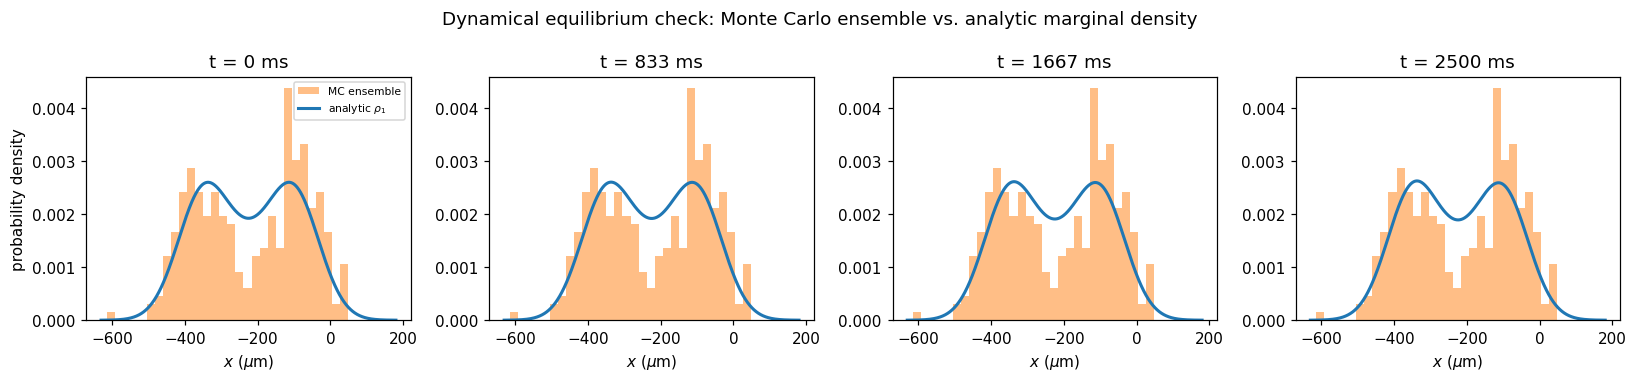

In [26]:
def marginal_density(x, t, p: Params):
    '''Analytic marginal density rho_1(x,t), unnormalised.'''
    O_ = branch_overlap(p.delta_x, p.sigma)
    dphi_LR, dphi_RL = gravitational_phases(t, p)
    w_LL, w_RR, w_LR = marginal_weights(dphi_LR, dphi_RL, O_)
    f, _ = density_and_grad(x, w_LL, w_RR, w_LR, uL1, uR1, p.sigma)
    return f

x_min = min(res["X1_B"].min(), uL1 - 4*p.sigma)
x_max = max(res["X1_B"].max(), uR1 + 4*p.sigma)
xs = np.linspace(x_min, x_max, 1500)

snapshot_fracs = [0.0, 1/3, 2/3, 1.0]
fig, axes = plt.subplots(1, len(snapshot_fracs), figsize=(15, 3.5), sharey=False)

for ax, frac in zip(axes, snapshot_fracs):
    idx_t = int(frac * p.n_steps)
    t_snap = res["t"][idx_t]
    rho = marginal_density(xs, t_snap, p)
    rho_normed = rho / np.trapezoid(rho, xs)
    ax.hist(res["X1_B"][idx_t]*1e6, bins=30, density=True, alpha=0.5, color="tab:orange",
            label="MC ensemble")
    ax.plot(xs*1e6, rho_normed*1e-6, color="tab:blue", lw=2, label=r"analytic $\rho_1$")
    ax.set_title(f"t = {t_snap*1e3:.0f} ms")
    ax.set_xlabel(r"$x$ ($\mu$m)")

axes[0].set_ylabel("probability density")
axes[0].legend(fontsize=7)
fig.suptitle("Dynamical equilibrium check: Monte Carlo ensemble vs. analytic marginal density")
fig.tight_layout()
plt.show()

The Monte Carlo histogram tracks the analytic marginal density at every snapshot, including the bimodal branch structure (peaks at the two branch positions) and its evolving relative weights as the phases accumulate. This confirms the Nelson ensemble correctly reproduces the Born-rule prediction throughout the simulation, not just initially — the stochastic-mechanics analogue of the dynamical equilibrium property used in the dissertation's deterministic feedback simulation.

## Part 9 — Discussion and conclusions

**What this notebook showed:**

1. The trajectory-based (dBB/CWF) feedback model and Nelson's stochastic mechanics share the same guidance velocity, exactly as the kinematic correspondence in the paper predicts. The only dynamical difference between Model A and Model B is the addition of the osmotic drift (sourced by the marginal density) and Brownian noise.
2. At the Bose et al. mass and timescale, gravity-driven *position* motion is far too small to resolve directly — both guidance and osmotic velocities are of order $10^{-18}\,$m/s. This is not a deficiency of the simulation; it reflects how weak gravity genuinely is at this mass scale.
3. The osmotic-velocity difference $\delta u^{\rm osm}_1$, by contrast, is a *phase*-sensitive diagnostic (built from the evolving branch weights, not from position displacement), and tracks entanglement growth cleanly: zero at $t=0$, growing quadratically with the accumulated differential phase, in close numerical agreement with the paper's stated relationship between $\delta u^{\rm osm}$ and the feedback term $F_2$.
4. The Monte Carlo ensemble of Nelson trajectories reproduces the analytically predicted marginal density at every snapshot in time — a dynamical-equilibrium-style consistency check, directly analogous to the one performed in the dissertation's Chapter 4 simulation, but now in the stochastic-mechanics setting.

**Limitations and natural next steps**, in increasing order of effort:

- **Exact feedback term $F_2$.** This notebook uses the *phase-based* comparison rather than literally evaluating the double time-integral defining $F_2$ in the paper, since a position-gradient-based proxy is dynamically frozen at this mass scale (we found this out explicitly in earlier exploratory work). A rigorous version would store the full trajectory history and evaluate the double integral directly — costing $O(N_{\rm steps}^2)$ per trajectory, but entirely feasible with `scipy.integrate.cumulative_trapezoid`.
- **Self-consistent (PDE) dynamics.** The closed-form $\Psi(t)$ used here is built from the idealised, kinetic-term-free Bose et al. phase formula. A fully self-consistent version would solve the coupled CWF equations numerically (Crank–Nicolson) using the true Newtonian potential, removing the idealisation entirely and letting the branch shapes themselves respond to the guidance dynamics.
- **Stronger-coupling exploration.** Increasing the mass (well beyond the BMV proposal) or decreasing the separation would make position-level guidance and osmotic effects large enough to resolve directly, which would be a useful pedagogical extension for visualising the feedback loop's effect on trajectories themselves, not just on $\delta u^{\rm osm}$.
- **Higher-order integrators.** The current Euler / Euler–Maruyama scheme is first order; RK4 (Model A) and a Milstein scheme (Model B) would improve accuracy for longer integration times.
